In [1]:
from google.colab import files

uploaded = files.upload()

Saving flood_dataset.zip to flood_dataset.zip


In [2]:
import zipfile
import os

zip_path = '/content/flood_dataset.zip'  # adjust if different
extract_path = '/content/flood_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Optional: check folder structure
os.listdir(extract_path)

['people in flood',
 'flood victims rescue',
 'people trapped in flood',
 'flood rescue drone people']

In [4]:
import os

base_path = '/content/flood_dataset'

# YOLO expected structure
train_dir = os.path.join(base_path, 'images/train')
val_dir = os.path.join(base_path, 'images/val')

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

label_train_dir = os.path.join(base_path, 'labels/train')
label_val_dir = os.path.join(base_path, 'labels/val')

os.makedirs(label_train_dir, exist_ok=True)
os.makedirs(label_val_dir, exist_ok=True)

In [6]:
import os
import shutil
import random

base_path = '/content/flood_dataset'

train_dir = os.path.join(base_path, 'images/train')
val_dir = os.path.join(base_path, 'images/val')

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)

all_images = []

# Collect all images from all query folders
for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)
    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):
            if file.endswith(('.jpg', '.png')):
                all_images.append(os.path.join(folder_path, file))

# Shuffle images
random.shuffle(all_images)

# Split
split = int(0.8 * len(all_images))
train_images = all_images[:split]
val_images = all_images[split:]

# Helper to move and rename
def move_and_rename(image_list, dest_dir, prefix):
    for idx, img_path in enumerate(image_list):
        ext = os.path.splitext(img_path)[1]
        new_name = f"{prefix}_{idx}{ext}"
        shutil.move(img_path, os.path.join(dest_dir, new_name))

# Move with unique names
move_and_rename(train_images, train_dir, "train")
move_and_rename(val_images, val_dir, "val")

print(f"Train images: {len(train_images)}, Val images: {len(val_images)}")

Train images: 416, Val images: 104


In [8]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [9]:
import os

train_dir = '/content/flood_dataset/images/train'
val_dir = '/content/flood_dataset/images/val'

# YOLO labels will be saved in these folders
label_train_dir = '/content/flood_dataset/labels/train'
label_val_dir = '/content/flood_dataset/labels/val'

os.makedirs(label_train_dir, exist_ok=True)
os.makedirs(label_val_dir, exist_ok=True)

# Auto-label train images
model.predict(
    source=train_dir,
    save_txt=True,       # saves bounding boxes in YOLO format
    save_conf=True,      # saves confidence score
    project='/content/flood_dataset',  # base folder for labels
    name='labels/train'
)

# Auto-label validation images
model.predict(
    source=val_dir,
    save_txt=True,
    save_conf=True,
    project='/content/flood_dataset',
    name='labels/val'
)


image 1/428 /content/flood_dataset/images/train/Image_106.jpg: 576x640 1 person, 1 vase, 44.0ms
image 2/428 /content/flood_dataset/images/train/Image_107.jpg: 448x640 3 persons, 44.5ms
image 3/428 /content/flood_dataset/images/train/Image_124.jpg: 384x640 4 persons, 1 car, 1 boat, 43.1ms
image 4/428 /content/flood_dataset/images/train/Image_128.jpg: 384x640 13 persons, 2 motorcycles, 2 umbrellas, 10.7ms
image 5/428 /content/flood_dataset/images/train/Image_2.jpg: 448x640 13 persons, 1 boat, 1 handbag, 13.4ms
image 6/428 /content/flood_dataset/images/train/Image_33.jpg: 384x640 1 boat, 11.3ms
image 7/428 /content/flood_dataset/images/train/Image_36.jpg: 640x640 3 persons, 1 car, 17.6ms
image 8/428 /content/flood_dataset/images/train/Image_69.jpg: 384x640 3 persons, 11.3ms
image 9/428 /content/flood_dataset/images/train/Image_73.jpg: 384x640 3 persons, 1 backpack, 1 surfboard, 10.7ms
image 10/428 /content/flood_dataset/images/train/Image_74.jpg: 448x640 7 persons, 3 cars, 1 airplane, 1 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted p

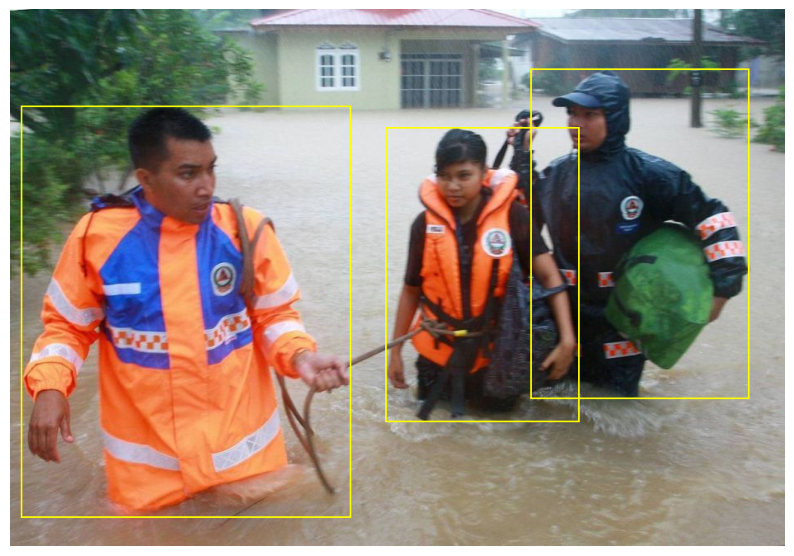

In [24]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

def visualize(image_path, label_path):
    img = Image.open(image_path)
    draw = ImageDraw.Draw(img)
    w, h = img.size

    # Draw boxes
    with open(label_path) as f:
        for line in f.readlines():
            cls, x_center, y_center, bw, bh = map(float, line.strip().split()[:5])
            x0 = (x_center - bw/2) * w
            y0 = (y_center - bh/2) * h
            x1 = (x_center + bw/2) * w
            y1 = (y_center + bh/2) * h
            draw.rectangle([x0, y0, x1, y1], outline="yellow", width=2)

    # Display inline in Colab
    plt.figure(figsize=(10,10))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

# Example usage
sample_img = '/content/flood_dataset/images/train/Image_107.jpg'
sample_label = '/content/flood_dataset/labels/train/labels/Image_107.txt'
visualize(sample_img, sample_label)

In [25]:
yaml_content = """
path: /content/flood_dataset
train: images/train
val: images/val

names:
  0: person
"""

with open('/content/flood_dataset.yaml', 'w') as f:
    f.write(yaml_content)

In [27]:
import os

label_path = '/content/flood_dataset/labels/train'
print(len(os.listdir(label_path)))

1


In [28]:
import shutil
import os

# Source (where YOLO actually saved)
src_train = '/content/flood_dataset/labels/train/labels'
src_val = '/content/flood_dataset/labels/val/labels'

# Destination (where YOLO expects)
dst_train = '/content/flood_dataset/labels/train'
dst_val = '/content/flood_dataset/labels/val'

# Move train labels
for file in os.listdir(src_train):
    shutil.move(os.path.join(src_train, file), dst_train)

# Move val labels
for file in os.listdir(src_val):
    shutil.move(os.path.join(src_val, file), dst_val)

print("Labels moved successfully")

Labels moved successfully


In [ ]:
import os

image_dir = '/content/flood_dataset/images/train'
label_dir = '/content/flood_dataset/labels/train'

image_names = set(os.path.splitext(f)[0] for f in os.listdir(image_dir))

for label in os.listdir(label_dir):
    label_path = os.path.join(label_dir, label)

    if os.path.isfile(label_path): 
        label_name = os.path.splitext(label)[0]
        if label_name not in image_names:
            os.remove(label_path)

print("Train labels cleaned.")

Train labels cleaned.


In [39]:
image_dir_val = '/content/flood_dataset/images/val'
label_dir_val = '/content/flood_dataset/labels/val'

image_names_val = set(os.path.splitext(f)[0] for f in os.listdir(image_dir_val))

for label in os.listdir(label_dir_val):
    label_path = os.path.join(label_dir_val, label)

    if os.path.isfile(label_path):  # ✅ avoid directories
        label_name = os.path.splitext(label)[0]
        if label_name not in image_names_val:
            os.remove(label_path)

print("Val labels cleaned.")

Val labels cleaned.


In [40]:
print("Train images:", len(os.listdir('/content/flood_dataset/images/train')))
print("Train labels:", len(os.listdir('/content/flood_dataset/labels/train')))

print("Val images:", len(os.listdir('/content/flood_dataset/images/val')))
print("Val labels:", len(os.listdir('/content/flood_dataset/labels/val')))

Train images: 410
Train labels: 410
Val images: 95
Val labels: 95


In [42]:
import os

def fix_labels(label_dir):
    for file in os.listdir(label_dir):
        file_path = os.path.join(label_dir, file)

        if os.path.isfile(file_path):
            with open(file_path, 'r') as f:
                lines = f.readlines()

            new_lines = []
            for line in lines:
                parts = line.strip().split()

                if len(parts) >= 5:
                    # Keep only first 5 values
                    new_lines.append(" ".join(parts[:5]) + "\n")

            with open(file_path, 'w') as f:
                f.writelines(new_lines)

# Apply to both train and val
fix_labels('/content/flood_dataset/labels/train')
fix_labels('/content/flood_dataset/labels/val')

print("Labels fixed (confidence removed).")

Labels fixed (confidence removed).


In [43]:
import os

cache_train = '/content/flood_dataset/labels/train.cache'
cache_val = '/content/flood_dataset/labels/val.cache'

if os.path.exists(cache_train):
    os.remove(cache_train)

if os.path.exists(cache_val):
    os.remove(cache_val)

print("Cache cleared.")

Cache cleared.


In [44]:
with open('/content/flood_dataset/labels/train/train_0.txt') as f:
    print(f.read())

37 0.0415368 0.411725 0.0827032 0.0840051
0 0.00532742 0.217763 0.0106214 0.133231



In [45]:
import os

def keep_only_person(label_dir):
    for file in os.listdir(label_dir):
        file_path = os.path.join(label_dir, file)

        if os.path.isfile(file_path):
            with open(file_path, 'r') as f:
                lines = f.readlines()

            new_lines = []
            for line in lines:
                parts = line.strip().split()

                if len(parts) >= 5:
                    cls = int(float(parts[0]))

                    if cls == 0:  # ✅ keep only person
                        new_lines.append(" ".join(parts[:5]) + "\n")

            # overwrite file
            with open(file_path, 'w') as f:
                f.writelines(new_lines)

# Apply to both
keep_only_person('/content/flood_dataset/labels/train')
keep_only_person('/content/flood_dataset/labels/val')

print("Filtered to only 'person' class.")

Filtered to only 'person' class.


In [46]:
def remove_empty_labels(image_dir, label_dir):
    for file in os.listdir(label_dir):
        file_path = os.path.join(label_dir, file)

        if os.path.isfile(file_path):
            if os.path.getsize(file_path) == 0:
                # remove label
                os.remove(file_path)

                # remove corresponding image
                img_name = os.path.splitext(file)[0]
                for ext in ['.jpg', '.png']:
                    img_path = os.path.join(image_dir, img_name + ext)
                    if os.path.exists(img_path):
                        os.remove(img_path)

# Apply
remove_empty_labels('/content/flood_dataset/images/train', '/content/flood_dataset/labels/train')
remove_empty_labels('/content/flood_dataset/images/val', '/content/flood_dataset/labels/val')

print("Removed empty labels and images.")

Removed empty labels and images.


In [47]:
import os

for path in [
    '/content/flood_dataset/labels/train.cache',
    '/content/flood_dataset/labels/val.cache'
]:
    if os.path.exists(path):
        os.remove(path)

print("Cache cleared.")

Cache cleared.


In [48]:
print("Train images:", len(os.listdir('/content/flood_dataset/images/train')))
print("Train labels:", len(os.listdir('/content/flood_dataset/labels/train')))

Train images: 380
Train labels: 380


In [49]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data='/content/flood_dataset.yaml',
    epochs=30,
    imgsz=640,
    batch=8,
    name='flood_victim_model_clean_final'
)

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flood_dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=flood_victim_model_clean_final, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pat

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79f426d67fb0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [50]:
from PIL import Image
import os

def downscale_images(image_dir, scale=0.5):
    for file in os.listdir(image_dir):
        path = os.path.join(image_dir, file)
        img = Image.open(path)
        w, h = img.size

        img = img.resize((int(w*scale), int(h*scale)))
        img.save(path)

# Apply (optional copy first if you want to preserve originals)
downscale_images('/content/flood_dataset/images/train', 0.6)

In [51]:
!pip install bing-image-downloader

In [53]:
from ultralytics import YOLO

# Load pretrained YOLOv8s
model = YOLO("yolov8s.pt")

model.train(
    data='/content/flood_dataset.yaml',  # your dataset YAML
    epochs=60,                           # longer training for robust augmentation
    imgsz=960,                            # higher resolution helps detect small UAV humans
    batch=6,                              # adjust for GPU memory
    name='flood_victim_augmented',        # experiment name

    # Augmentation parameters
    hsv_h=0.015,      # hue
    hsv_s=0.7,        # saturation
    hsv_v=0.4,        # brightness/value
    degrees=15,       # rotate ±15 degrees
    scale=0.5,        # random scale
    translate=0.1,    # shift images by 10%
    flipud=0.5,       # vertical flip probability
    fliplr=0.5,       # horizontal flip probability
    mosaic=True,      # combines 4 images → robust for small objects
    mixup=True        # blend 2 images → better for occluded victims
)

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flood_dataset.yaml, degrees=15, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=True, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=True, multi_scale=0.0, name=flood_victim_augmented, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79f42776d7f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [54]:
# UAV augmentations
aug_params = {
    'degrees': 15,        # rotation
    'scale': 0.5,         # zoom in/out
    'translate': 0.1,     # image shift
    'flipud': 0.5,        # vertical flip
    'fliplr': 0.5,        # horizontal flip
    'hsv_h': 0.015,       # hue
    'hsv_s': 0.7,         # saturation
    'hsv_v': 0.4,         # brightness/value
    'mosaic': True,       # combine 4 images → helps small object detection
    'mixup': True         # blend two images → robust occlusions
}

# Loss weighting (optional: emphasize person detection)
hyp_params = {
    'box': 0.05,  # box loss weight (helps small objects)
    'cls': 0.7,
    'obj': 0.5
}

In [57]:
from ultralytics import YOLO

# Load pretrained YOLOv8
model = YOLO("yolov8s.pt")  # use 'yolov8m.pt' if GPU allows

# UAV-specific augmentations
model.train(
    data="/content/flood_dataset.yaml",
    epochs=80,
    imgsz=960,
    batch=6,
    lr0=0.001,        # smaller learning rate
    name="flood_uav_model_final",

    # Augmentations
    degrees=15,
    scale=0.5,
    translate=0.1,
    flipud=0.5,
    fliplr=0.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    mosaic=True,
    mixup=True
)

Ultralytics 8.4.23 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/flood_dataset.yaml, degrees=15, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=True, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=True, multi_scale=0.0, name=flood_uav_model_final, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79f40eb09640>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [58]:
from ultralytics import YOLO

# Load the trained model from your last run
model = YOLO("/content/runs/detect/flood_uav_model_final/weights/best.pt")

In [59]:
example_image = "/content/flood_dataset/images/val/val_1.jpg"  # update path to any UAV image

In [60]:
results = model.predict(
    source=example_image,
    conf=0.25,    # confidence threshold (lower for higher recall)
    save=True,    # saves the annotated image
    show=True     # displays the image in Colab
)

WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()


image 1/1 /content/flood_dataset/images/val/val_1.jpg: 544x960 1 person, 115.2ms
Speed: 8.8ms preprocess, 115.2ms inference, 2.1ms postprocess per image at shape (1, 3, 544, 960)
Results saved to /content/runs/detect/predict


In [61]:
import shutil
import os

os.makedirs("/content/models", exist_ok=True)

# Copy baseline
shutil.copy(
    "/content/runs/detect/flood_victim_model_clean_final/weights/best.pt",
    "/content/models/flood_victim_baseline.pt"
)

# Copy UAV model
shutil.copy(
    "/content/runs/detect/flood_uav_model_final/weights/best.pt",
    "/content/models/flood_victim_uav.pt"
)

'/content/models/flood_victim_uav.pt'

In [62]:
from ultralytics import YOLO

val_folder = "/content/flood_dataset/images/val"
save_folder = "/content/models/test_predictions"
os.makedirs(save_folder, exist_ok=True)

# Baseline model
baseline_model = YOLO("/content/models/flood_victim_baseline.pt")
baseline_model.predict(source=val_folder, conf=0.25, save=True, project=save_folder, name="baseline")

# UAV model
uav_model = YOLO("/content/models/flood_victim_uav.pt")
uav_model.predict(source=val_folder, conf=0.25, save=True, project=save_folder, name="uav")


image 1/92 /content/flood_dataset/images/val/val_0.jpg: 480x640 4 persons, 25.2ms
image 2/92 /content/flood_dataset/images/val/val_1.jpg: 384x640 1 person, 36.5ms
image 3/92 /content/flood_dataset/images/val/val_10.jpg: 448x640 3 persons, 17.1ms
image 4/92 /content/flood_dataset/images/val/val_100.jpg: 512x640 9 persons, 19.6ms
image 5/92 /content/flood_dataset/images/val/val_101.jpg: 448x640 3 persons, 26.5ms
image 6/92 /content/flood_dataset/images/val/val_103.jpg: 384x640 7 persons, 31.8ms
image 7/92 /content/flood_dataset/images/val/val_11.jpg: 384x640 5 persons, 10.9ms
image 8/92 /content/flood_dataset/images/val/val_12.jpg: 480x640 10 persons, 26.4ms
image 9/92 /content/flood_dataset/images/val/val_15.jpg: 448x640 9 persons, 16.0ms
image 10/92 /content/flood_dataset/images/val/val_16.jpg: 448x640 1 person, 12.8ms
image 11/92 /content/flood_dataset/images/val/val_17.jpg: 640x480 10 persons, 20.7ms
image 12/92 /content/flood_dataset/images/val/val_18.jpg: 384x640 2 persons, 16.7ms

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'person'}
 obb: None
 orig_img: array([[[ 79,  79,  63],
         [ 73,  73,  57],
         [ 85,  85,  69],
         ...,
         [ 48,  67,  58],
         [ 54,  79,  69],
         [ 60,  90,  79]],
 
        [[ 70,  70,  54],
         [ 76,  76,  60],
         [ 95,  95,  79],
         ...,
         [ 51,  72,  63],
         [ 53,  78,  68],
         [ 60,  90,  79]],
 
        [[ 65,  65,  49],
         [ 80,  80,  64],
         [103, 103,  87],
         ...,
         [ 61,  85,  75],
         [ 55,  82,  72],
         [ 63,  93,  82]],
 
        ...,
 
        [[ 77,  99, 110],
         [ 78, 100, 111],
         [ 80, 102, 113],
         ...,
         [ 75, 113, 131],
         [ 77, 115, 133],
         [ 72, 110, 128]],
 
        [[ 71,  93, 104],
         [ 78, 100, 111],
         [ 85, 107, 118],
         ...,
         [ 72, 110

In [63]:
!zip -r /content/flood_models_and_predictions.zip /content/models

  adding: content/models/ (stored 0%)
  adding: content/models/test_predictions/ (stored 0%)
  adding: content/models/test_predictions/uav/ (stored 0%)
  adding: content/models/test_predictions/uav/val_6.jpg (deflated 4%)
  adding: content/models/test_predictions/uav/val_72.jpg (deflated 4%)
  adding: content/models/test_predictions/uav/val_44.jpg (deflated 1%)
  adding: content/models/test_predictions/uav/val_5.jpg (deflated 4%)
  adding: content/models/test_predictions/uav/val_101.jpg (deflated 1%)
  adding: content/models/test_predictions/uav/val_57.jpg (deflated 4%)
  adding: content/models/test_predictions/uav/val_24.jpg (deflated 3%)
  adding: content/models/test_predictions/uav/val_93.jpg (deflated 4%)
  adding: content/models/test_predictions/uav/val_99.jpg (deflated 2%)
  adding: content/models/test_predictions/uav/val_77.jpg (deflated 7%)
  adding: content/models/test_predictions/uav/val_95.jpg (deflated 0%)
  adding: content/models/test_predictions/uav/val_51.jpg (deflated 3